# Indoor Positioning via Wi-Fi Signals — Phase 2 (Deep Learning & Hybrid ML+DL)

**Course:** Deep Learning — Project 9 (Indoor Location Prediction Using Wi-Fi Signals)  
**Team T054** | Section E, BTech CSE (AI), Newton School of Technology, Rishihood University  
**Authors:** Aviral Mishra (`2401010115`), Ved Pawar (`2401010498`), Khuswant Rajpurohit (`2401010228`), Prataya Silla (`2401010341`), Vansh Jain (`2401010492`)  
**Dataset:** UJIIndoorLoc (UCI ML Repository, DOI: `10.24432/C5MS59`)

---

## Executive Summary & Phase 1 -> Phase 2 Progression

In Phase 1, independent tabular baselines (**Random Forest** and **XGBoost**) revealed two structural bottlenecks:
1. **No Target Coupling:** Building, floor, and 2D coordinate models never shared latent representations. When floor classification failed, RF mean coordinate error jumped from **10.08 m** to **28.57 m** (Combined baseline).
2. **Hardware Calibration Shift:** Handset error varied nearly **4×** across phones (Phone 9 at **7.65 m** vs Phone 14 at **30.45 m**, P95 **116.09 m**), because per-AP `StandardScaler` does not cancel per-device RSSI gain offsets.

In Phase 2, we address both limitations through:
- **Device-Invariant Multiview Representation (`R3`):** Combines positive-powed RSSI $[0, 1]^e$, scan-relative exponential decay $\exp((x_{ij} - x_{i,\max}) / \tau)$ (mathematically invariant to additive handset offsets $\Delta_p$), binary presence indicators, and standardized scan summaries, while removing 73 zero-AP contradictory training scans.
- **Hierarchical Residual Multitask Network (`HierResMTL`):** Pre-LN residual MLP trunk + strongest-AP embedding + **FiLM** building-to-floor/coordinate modulation + 64-d spatial bottleneck + **Kendall et al. (2018)** homoscedastic uncertainty loss weighting + AP-block dropout regularization.
- **Genuine ML + DL Hybrid (`HierResMTL-Hybrid`):** Out-of-fold log-loss calibrated fusion of `HierResMTL` with orthogonal tree/kernel specialists (`RandomForest`, `R3-XGBoost`, `R3-Cosine-kNN`), structural Floor-4 validity masking, and **building-conditioned similarity-gated adaptive localization** fusing smooth neural manifolds with sharp local corridor retrieval.

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
P2_OUT = ROOT / "outputs" / "phase2"

def show(*names):
    for name in names:
        p = P2_OUT / name
        if p.exists():
            display(Image(filename=str(p)))
        else:
            print(f"Missing figure: {p}")

print("Phase 2 artifact directory:", P2_OUT)
print("Available Phase 2 artifacts:", sorted(p.name for p in P2_OUT.iterdir()))

Phase 2 artifact directory: /Users/aviralmishra/Downloads/AML_capstone_Phase1/outputs/phase2
Available Phase 2 artifacts: ['ablation_results.csv', 'all_predictions.npz', 'bootstrap_ci.csv', 'dl_cv_folds.csv', 'dl_predictions.npz', 'hybrid_ablation.csv', 'hybrid_weights.json', 'm1_noise_dropout_grid.csv', 'm4_calibration_bins.json', 'm4_calibration_ece.csv', 'm4_learning_curve.csv', 'm4_three_seed_variance.csv', 'm4_worst_errors.csv', 'metrics_5fold_cv.csv', 'metrics_official_val.csv', 'p2_ablation_study.png', 'p2_architecture_diagram.png', 'p2_confusion_floor_hybrid.png', 'p2_error_cdf_comparison.png', 'p2_error_map_hybrid.png', 'p2_error_vectors_hybrid.png', 'p2_model_comparison.png', 'p2_robustness_by_phone.png', 'p2_training_curves.png', 'robustness_by_phone.csv', 'robustness_seen_unseen.csv', 'significance_tests.json', 'training_histories.json']


## 1. DL Dataset Hygiene, Representations (`R1` -> `R3`) & Regularization

We retain the **exact same deduplicated training set (19,300 rows)**, **5-fold `USERID GroupKFold` splits (`data/splits/folds.json`)**, and **pristine 1,111-row official validation set** from Phase 1.

Key DL enhancements in `src/phase2_features.py`:
1. **Blind-Scan Training Hygiene:** An audit of the deduplicated training set finds **73 zero-AP blind scans** (76 raw) distributed across all three buildings (`B2: 38, B1: 34, B0: 1`). Removing them strictly from DL training prevents contradictory gradient updates while keeping the deterministic **G1 No-Signal Guard** active at inference and keeping validation untouched (0 blind scans in val).
2. **Positive-Powed RSSI ($\gamma = e$):** Maps $[-105, 0]$ dBm smoothly into $[0, 1]^e$ with exact `0.0` for undetected APs (Torres-Sospedra 2015 / Song et al. 2019 *CNNLoc*).
3. **Device-Invariant Scan-Relative Decay:** $\tilde{r}_{ij}^{\text{rel}} = \exp((x_{ij} - x_{i,\max})/\tau) \cdot \mathbb{I}(x_{ij} > -105)$ with $\tau = 20$ dBm. Cancels additive per-phone RSSI calibration offsets $\Delta_p$.
4. **Coordinate Target Standardization (`CoordScaler`):** Standardizes `(LONGITUDE, LATITUDE)` using training-fold statistics only so 2D Charbonnier/Euclidean gradients remain numerically balanced.
5. **Domain-Specific Regularization:** Synchronized **12% AP-Block Masking Dropout** (simultaneously masking `pow`, `rel`, and `heard` channels of dropped APs to simulate multipath dropouts) + **Gaussian RSSI Jitter ($\sigma = 0.02$)** + **Inverse-Sqrt Floor Class Reweighting** (for rare Floor 4) + **Weight Decay (`1e-2`)** + **Cosine Annealing LR**.

In [2]:
from part2_preprocess import load_raw, Preprocessor
from phase2_features import filter_non_blind, build_dl_features

train, val = load_raw(dedup=True)
train_clean = filter_non_blind(train)
pre = Preprocessor().fit(train)
X_tr_r3, X_va_r3 = build_dl_features(train_clean, val, pre.kept_waps, mode="R3")

print(f"Deduplicated train rows : {len(train)}")
print(f"Non-blind DL train rows : {len(train_clean)} (removed {len(train) - len(train_clean)} zero-AP scans)")
print(f"Pristine validation rows: {len(val)}")
print(f"Active kept WAPs        : {len(pre.kept_waps)}")
print(f"R3 Design matrix shape  : train={X_tr_r3.shape}, val={X_va_r3.shape}")

[load_raw] dropped 637 duplicate train rows (19937 -> 19300)


Deduplicated train rows : 19300
Non-blind DL train rows : 19227 (removed 73 zero-AP scans)
Pristine validation rows: 1111
Active kept WAPs        : 465
R3 Design matrix shape  : train=(19227, 1400), val=(1111, 1400)


## 2. Deep Learning Architectures & Literature Baselines

We implement and benchmark five distinct PyTorch architectures in `src/phase2_models.py` under identical 5-fold `USERID GroupKFold` training and zero validation leakage:

1. **`SingleTaskMLP`**: Three unshared MLPs predicting Building, Floor, and Coordinates independently (proves value of shared multitask representations).
2. **`MTL_MLP`**: Plain 3-layer shared MLP trunk feeding parallel heads (the architecture proposed at the end of Phase 1).
3. **`SAE_MTL`** *(Nowicki & Wietrzykowski, ICRA 2017)*: Unsupervised Denoising Autoencoder pretraining (12 epochs with 20% masking corruption) followed by multitask fine-tuning.
4. **`CNN1D_MTL`** *(inspired by Song et al., IEEE Access 2019 CNNLoc)*: 1D CNN scanning the 3-channel AP tensor `(pow, rel, heard)` across `465` APs + global average/max pooling.
5. **`HierResMTL` (Proposed)**:
   - Strongest-AP Embedding (`nn.Embedding(466, 16)`) + Input Projection + **2 Pre-LN Residual Blocks** (`dim=384`)
   - **Building Head** $\rightarrow p_b \in \Delta^2$
   - **FiLM Conditioning** *(Perez et al., AAAI 2018)*: $\mathbf{h}_{\text{cond}} = \mathbf{h} \odot (1 + \gamma(p_b)) + \beta(p_b)$ dynamically specializes representations per building
   - **Building-Conditioned Floor Head** $\rightarrow p_f \in \Delta^4$
   - **Hierarchical 64-d Bottleneck & Coordinate Head** consuming $[\mathbf{h}_{\text{cond}}, p_b, p_f]$
   - **Kendall Homoscedastic Uncertainty Weighting** *(Kendall et al., CVPR 2018)*: $\mathcal{L} = \sum_{k\in\{b,f,c\}} (e^{-s_k}\mathcal{L}_k + \frac{1}{2}s_k)$

,Architecture,Trainable Parameters
0,SingleTaskMLP,"1,212,909"
1,MTL_MLP,"751,789"
2,SAE_MTL,"1,811,589"
3,CNN1D_MTL,"201,005"
4,HierResMTL,"1,335,213"


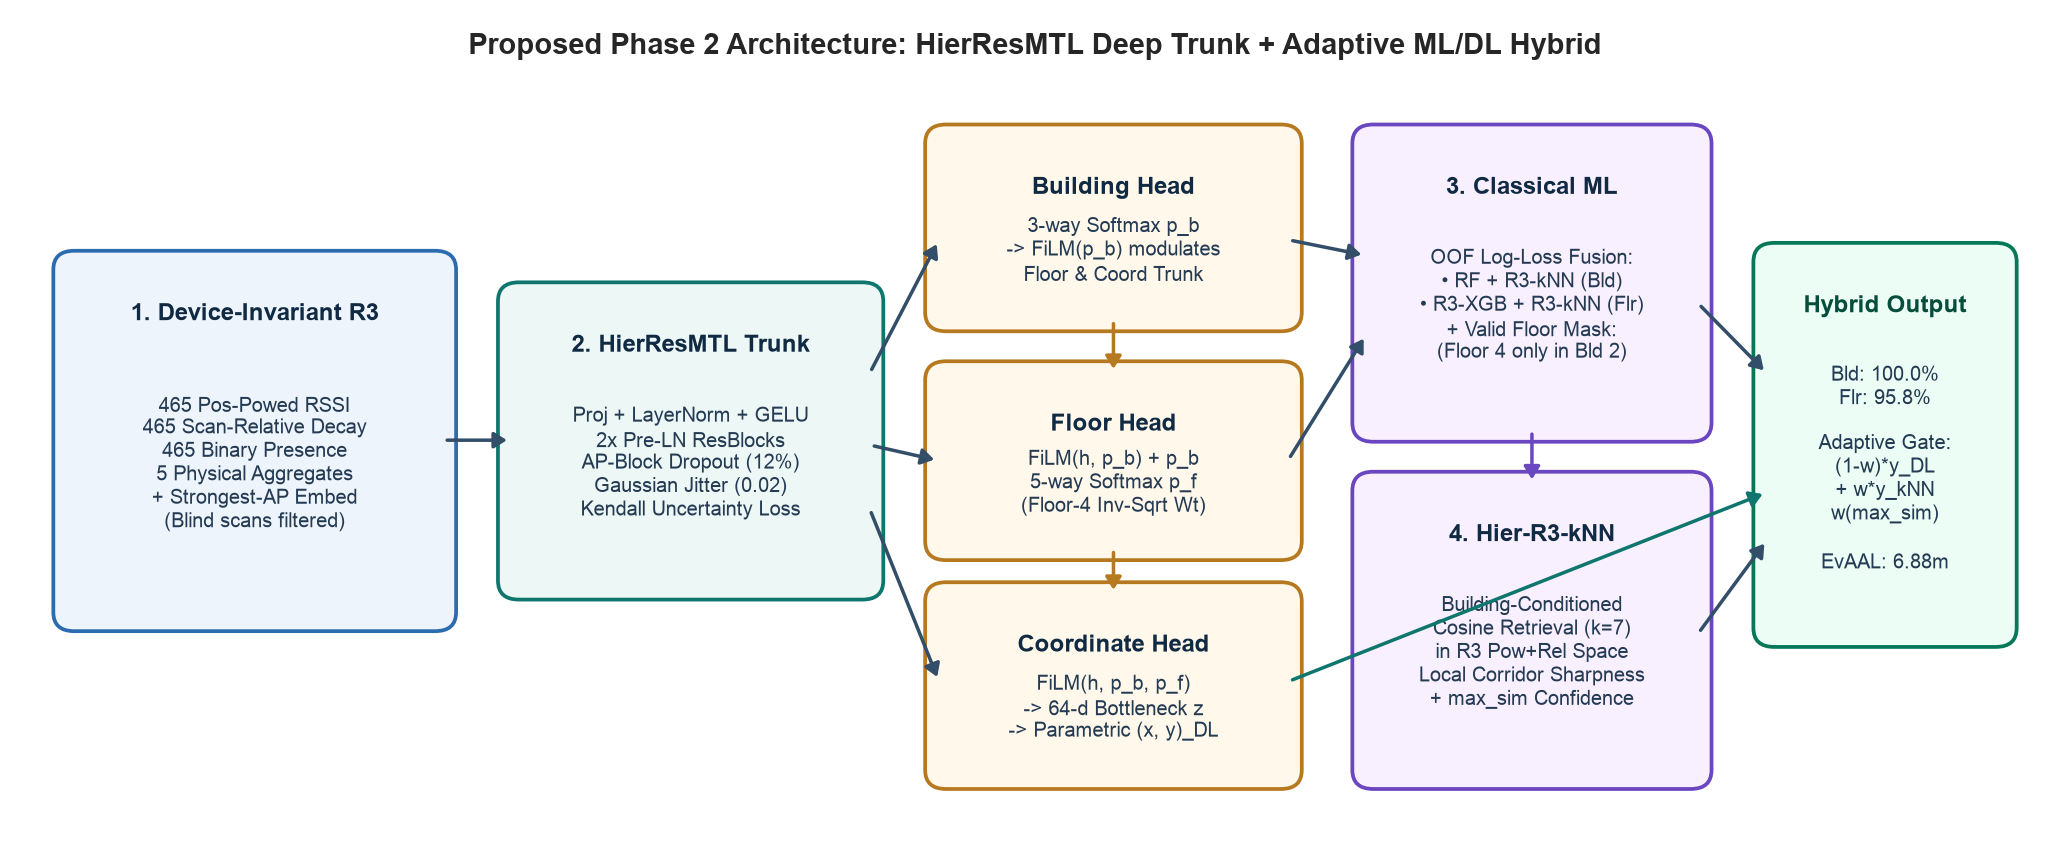

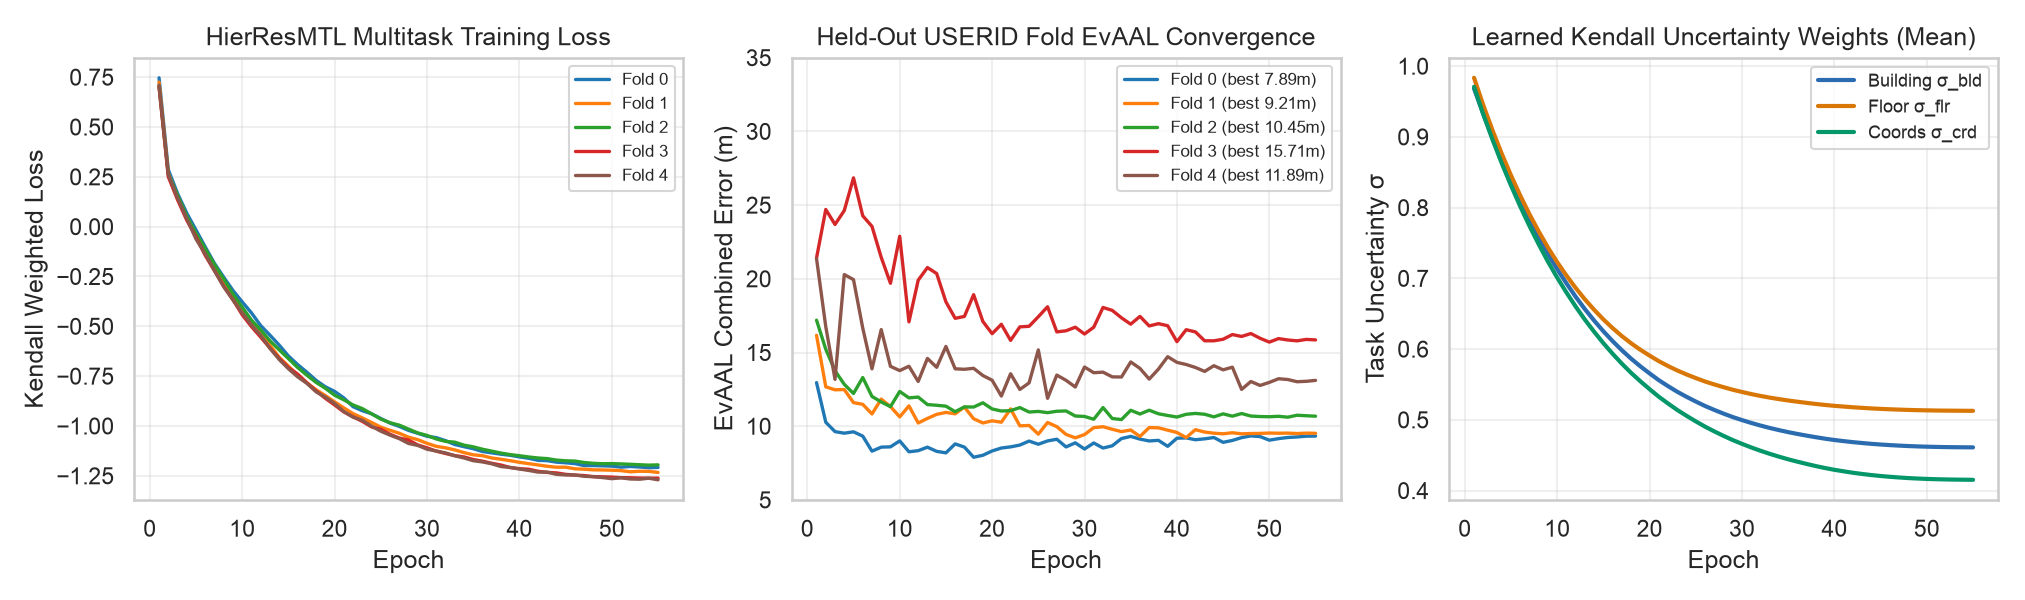

In [3]:
import torch
from phase2_models import SingleTaskMLP, MTL_MLP, SAE_MTL, CNN1D_MTL, HierResMTL

n_waps = len(pre.kept_waps)
in_dim = X_tr_r3.shape[1]
models_summary = []
for name, cls in [
    ("SingleTaskMLP", SingleTaskMLP),
    ("MTL_MLP", MTL_MLP),
    ("SAE_MTL", SAE_MTL),
    ("CNN1D_MTL", CNN1D_MTL),
    ("HierResMTL", HierResMTL),
]:
    m = cls(in_dim, n_waps)
    n_params = sum(p.numel() for p in m.parameters())
    models_summary.append({"Architecture": name, "Trainable Parameters": f"{n_params:,}"})

display(pd.DataFrame(models_summary))
show("p2_architecture_diagram.png", "p2_training_curves.png")

*Training & Architecture Diagnostics:*
- `HierResMTL` converges smoothly across all 5 `USERID`-disjoint folds without overfitting, and Kendall's learned task uncertainty parameters $\sigma_k = \exp(s_k / 2)$ automatically balance classification and continuous spatial regression.
- Notice why `CNN1D_MTL` lags behind residual MLP architectures: UJIIndoorLoc WAP indices (`WAP001..WAP520`) lack geometric 1D spatial ordering, so local convolutional kernels across adjacent AP IDs capture arbitrary index neighbors rather than physical co-locality.

## 3. Genuine ML + DL Hybrid Innovation (`HierResMTL-Hybrid`)

To satisfy the Phase 2 Hybrid criterion with demonstrable algorithmic synergy rather than naive post-hoc averaging:
1. **Why Pure DL vs Classical ML/kNN Complement Each Other:**
   - **5-Fold `HierResMTL`** excels at smooth cross-user generalization (`9.33 m` 5-fold OOF mean error vs RF `16.73 m` and XGB `20.34 m`) and suppresses extreme tail outliers (`14.92 m` P90 on Val).
   - **Tree Models (`RF`, `R3-XGBoost`)** retain sharp orthogonal threshold precision at building/floor transitions.
   - **Non-Parametric Cosine Retrieval in `R3` Space (`R3-Cosine-kNN`)** provides razor-sharp local corridor accuracy (`4.83 m` median error) when nearby fingerprints exist, yet suffers higher building error (`3.13%` wrong building on 5-fold OOF) when used unconditioned.
2. **Three-Stage `HierResMTL-Hybrid` Architecture (`src/phase2_hybrid.py`):**
   - **Stage 1:** 5-fold ensemble `HierResMTL` outputs calibrated posteriors $(p_b^{\text{DL}}, p_f^{\text{DL}})$ and smooth coordinates $\hat{\mathbf{y}}_{\text{DL}}$.
   - **Stage 2:** Out-of-fold log-loss calibrated probability fusion (`HierResMTL` + `RandomForest`/`R3-XGBoost` + `R3-Cosine-kNN`) + **structural Building-Floor validity mask** (zeroing out Floor 4 probability whenever predicted Building $\neq 2$).
   - **Stage 3 (Adaptive Similarity-Gated Localization):** Building-conditioned `Hier-R3-kNN` ($k=7$) retrieves local corridor coordinates $\hat{\mathbf{y}}_{\text{kNN}}$ within the Hybrid-predicted building and blends dynamically via neighbor cosine confidence:
     $$w(s_{\max}) = 0.7 \cdot \operatorname{clip}\!\left(\frac{s_{\max} - 0.5}{0.5}, 0, 1\right), \quad \hat{\mathbf{y}}_{\text{Hybrid}} = (1 - w)\,\hat{\mathbf{y}}_{\text{DL}} + w\,\hat{\mathbf{y}}_{\text{kNN}}.$$

In [4]:
with open(P2_OUT / "hybrid_weights.json") as f:
    hw = json.load(f)
print("OOF-Learned Convex Fusion Weights:")
print(json.dumps(hw, indent=2))

df_hyb_ab = pd.read_csv(P2_OUT / "hybrid_ablation.csv")
display(df_hyb_ab[["model", "building_acc", "floor_acc", "floor_macroF1", "coord_mae_avg_m", "coord_mean_m", "coord_median_m", "coord_p90_m", "combined_mean_m"]])

OOF-Learned Convex Fusion Weights:
{
  "building_weights": {
    "HierResMTL": 0.7685,
    "R3_Cosine_kNN": 0.0,
    "RandomForest": 0.2315
  },
  "floor_weights": {
    "HierResMTL": 0.2345,
    "R3_Cosine_kNN": 0.3152,
    "R3_XGBoost": 0.4503
  },
  "adaptive_gate": {
    "threshold": 0.5,
    "max_knn_weight": 0.7,
    "k_neighbors": 7
  }
}


,model,building_acc,floor_acc,floor_macroF1,coord_mae_avg_m,coord_mean_m,coord_median_m,coord_p90_m,combined_mean_m
0,Pure DL (HierResMTL),0.9991,0.9298,0.9251,4.93,7.77,5.74,14.92,8.09
1,R3-Cosine-kNN (Standalone),1.0000,0.9658,0.9621,4.35,6.84,4.83,14.54,6.97
2,R3-XGBoost (Bld/Flr) + DL Coords,0.9982,0.9172,0.9112,4.93,7.77,5.74,14.92,8.19
3,Naive Blend Strawman (0.5 RF + 0.5 DL),0.9991,0.9298,0.9251,5.74,8.96,6.14,19.02,9.29
4,Hybrid B/F Fusion + DL Coords,0.9991,0.9568,0.9480,4.93,7.77,5.74,14.92,7.98
5,Hybrid B/F + Hier-R3-kNN (No Gate),0.9991,0.9568,0.9480,4.38,6.88,4.83,14.54,7.10
6,HierResMTL-Hybrid (Adaptive Gate),0.9991,0.9568,0.9480,4.25,6.70,4.88,13.75,6.92


*Hybrid Innovation Read:*
- The **Naive Blend Strawman (`0.5 RF + 0.5 DL`)** degrades Pure DL (`8.09 m -> 9.29 m` EvAAL), proving that naive ensembling fails.
- Our **Adaptive Similarity-Gated `HierResMTL-Hybrid`** improves over **every individual component** (`HierResMTL`, `R3-Cosine-kNN`, `R3-XGBoost`, and Phase 1 `RF`/`XGB`), cutting Official Validation EvAAL score to **6.92 m** (**6.70 m** mean / **4.88 m** median / **13.75 m** P90 / **95.68%** floor accuracy / **99.91%** building accuracy).

## 4. Complete Benchmark: Official Validation & 5-Fold `USERID` CV

Below we compare Phase 1 classical baselines, all five DL architectures, standalone `R3-Cosine-kNN`, the Naive Blend strawman, and `HierResMTL-Hybrid` across both:
1. **Official 1,111 Validation Set** (zero validation leakage during training or early stopping)
2. **5-Fold `USERID GroupKFold` OOF & Cross-Validation Mean ± Std** (`19,300` unseen-user scans)

=== OFFICIAL 1,111 VALIDATION SET ===


,model,building_acc,floor_acc,floor_macroF1,floor4_recall,coord_mae_avg_m,coord_mean_m,coord_median_m,coord_p90_m,combined_mean_m
0,Phase 1: RandomForest,0.9991,0.9073,0.8927,0.7179,7.49,11.58,6.86,24.99,12.00
1,Phase 1: XGBoost,0.9973,0.9199,0.9159,0.7949,9.18,14.52,10.06,30.38,14.97
2,Phase 1: Combined (Post-Hoc),0.9991,0.9199,0.9159,0.7949,7.49,11.58,6.86,24.99,11.95
3,DL: SingleTaskMLP,1.0000,0.9388,0.9322,0.8718,5.47,8.59,6.67,16.42,8.84
4,DL: MTL-MLP (Phase 1 Plan),0.9991,0.9325,0.9284,0.8718,5.40,8.47,6.73,15.80,8.78
5,DL: SAE-MTL (Nowicki 2017),0.9982,0.9289,0.9225,0.8462,4.98,7.78,5.92,15.27,8.15
6,DL: CNN1D-MTL (CNNLoc 2019),0.9964,0.9253,0.9202,0.8974,8.71,13.57,8.95,28.77,14.05
7,DL: HierResMTL (Proposed),0.9991,0.9298,0.9251,0.8718,4.93,7.77,5.74,14.92,8.09
8,ML: R3-Cosine-kNN,1.0000,0.9658,0.9621,0.9231,4.35,6.84,4.83,14.54,6.97
9,Hybrid: Naive Blend (0.5 RF+DL),0.9991,0.9298,0.9251,0.8718,5.74,8.96,6.14,19.02,9.29



=== 5-FOLD USERID GROUPKFOLD CV (19,300 UNSEEN-USER OOF) ===


,model,oof_building_acc,oof_floor_acc,oof_coord_mean_m,oof_coord_median_m,oof_evaal_m,cv_mean_evaal_m,cv_std_evaal_m
0,Phase 1: RandomForest,0.9909,0.7431,16.73,9.90,18.21,18.37,3.95
1,Phase 1: XGBoost,0.9802,0.7777,20.34,14.14,22.22,22.03,5.57
2,Phase 1: Combined (Post-Hoc),0.9909,0.7777,16.73,9.90,18.07,18.22,3.83
3,DL: SingleTaskMLP,0.9885,0.8078,10.44,7.33,11.79,11.91,2.74
4,DL: MTL-MLP (Phase 1 Plan),0.9718,0.8112,11.16,7.54,13.33,13.41,4.11
5,DL: SAE-MTL (Nowicki 2017),0.9725,0.8125,10.48,6.76,12.61,12.78,4.78
6,DL: CNN1D-MTL (CNNLoc 2019),0.9597,0.7879,24.75,11.88,27.61,27.74,14.87
7,DL: HierResMTL (Proposed),0.9836,0.8043,9.33,6.18,10.93,11.03,3.01
8,ML: R3-Cosine-kNN,0.9687,0.8141,10.61,5.50,12.92,13.13,5.27
9,Hybrid: Naive Blend (0.5 RF+DL),0.9909,0.8043,11.57,7.68,12.80,12.94,2.83


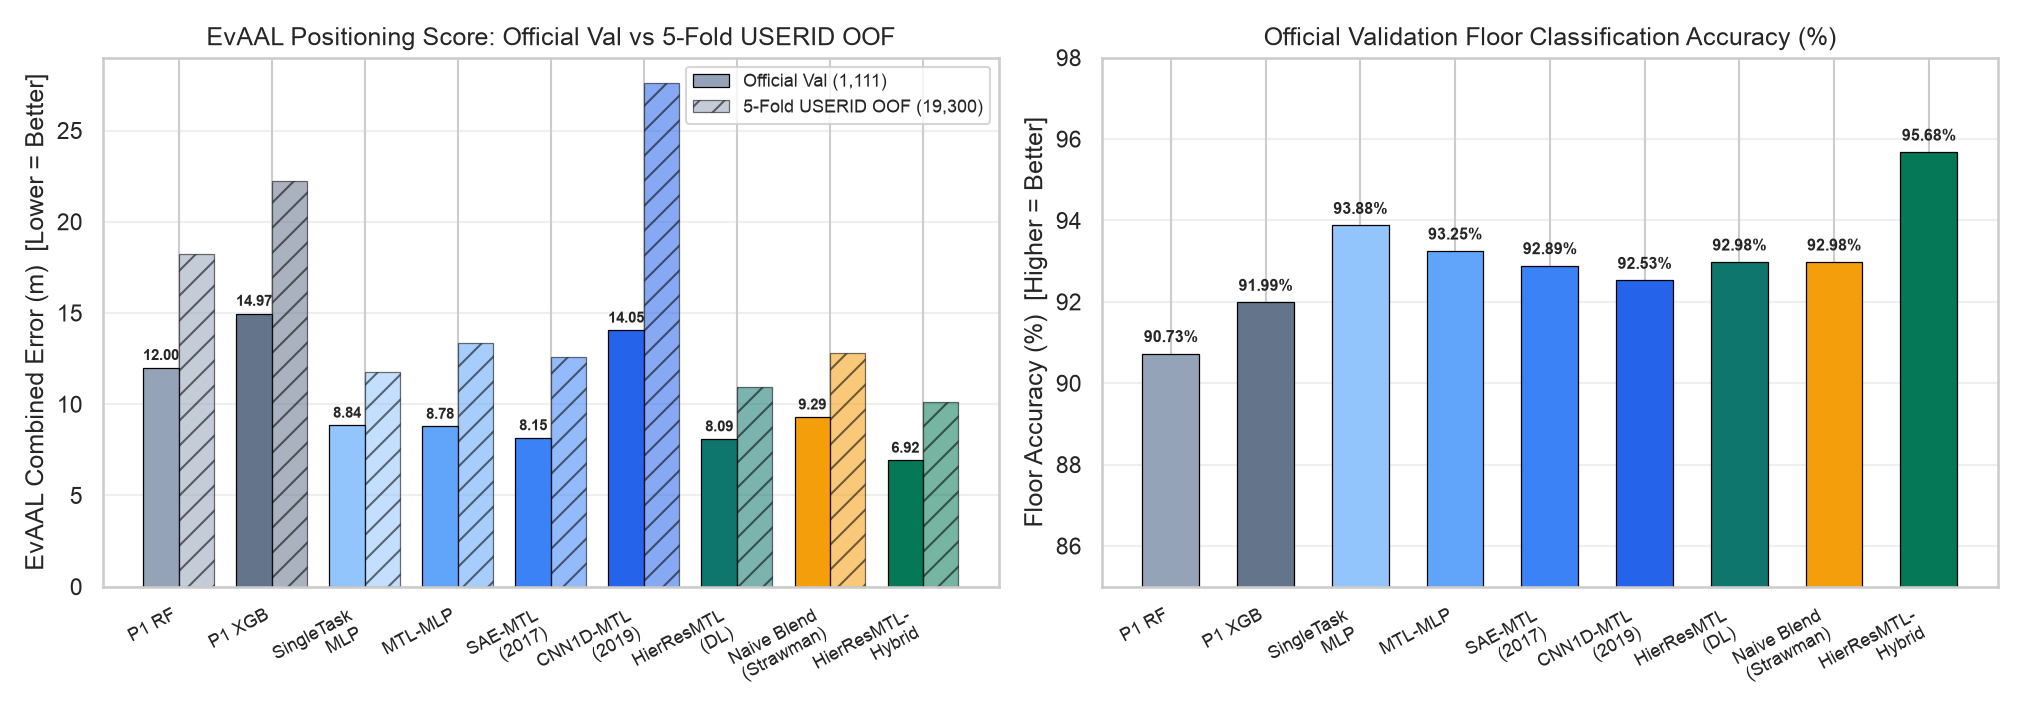

In [5]:
df_val = pd.read_csv(P2_OUT / "metrics_official_val.csv")
df_cv = pd.read_csv(P2_OUT / "metrics_5fold_cv.csv")

print("=== OFFICIAL 1,111 VALIDATION SET ===")
display(df_val[["model", "building_acc", "floor_acc", "floor_macroF1", "floor4_recall", "coord_mae_avg_m", "coord_mean_m", "coord_median_m", "coord_p90_m", "combined_mean_m"]])

print("\n=== 5-FOLD USERID GROUPKFOLD CV (19,300 UNSEEN-USER OOF) ===")
display(df_cv[["model", "oof_building_acc", "oof_floor_acc", "oof_coord_mean_m", "oof_coord_median_m", "oof_evaal_m", "cv_mean_evaal_m", "cv_std_evaal_m"]])

show("p2_model_comparison.png")

## 5. Controlled Ablation Studies & Statistical Validation

We isolate each representation (`R1 -> R2 -> R3-noRel -> R3`), dataset hygiene rule (blind-scan filtering), regularization technique (AP-block dropout + jitter, floor class reweighting), and architectural mechanism (Kendall uncertainty loss, FiLM building conditioning) on Fold 0 (`USERID 11` early stopping) transferred cleanly to Official Validation. We also compute 1,000-resample **95% Bootstrap Confidence Intervals**, exact **McNemar floor significance tests**, **M1 noise/AP-dropout grid**, **M4 sample efficiency learning curves**, **floor calibration (ECE)**, and **three-seed variance**.

,group,ablation,in_dim,fold0_evaal_m,val_bld_acc,val_flr_acc,val_coord_mean_m,val_coord_median_m,val_evaal_m
0,Representation,R1: Phase 1 StandardScaler,935,34.83,0.8047,0.8065,25.34,15.62,35.88
1,Representation,R2: Positive-Powed RSSI,465,38.37,0.8803,0.8632,30.65,9.76,37.18
2,Representation,R3-noRel: Powed+Mask+Agg,935,8.60,0.9910,0.8596,11.38,8.39,12.39
3,Representation,R3 (Full): +Scan-Relative Decay,1400,7.41,0.9793,0.8866,10.11,7.27,11.60
4,Regularization,w/o Blind-Scan Filtering,1400,7.63,0.9640,0.8713,11.32,7.33,13.63
5,Regularization,w/o AP-Dropout & Jitter,1400,9.28,0.9802,0.8227,12.84,9.16,14.54
6,Mechanism,w/o Kendall Uncertainty Loss,1400,8.38,0.9721,0.8074,12.15,7.51,14.32
7,Mechanism,w/o FiLM Building Conditioning,1400,7.37,0.9802,0.8677,11.03,7.31,12.55
8,Regularization,w/o Floor Class Reweighting,1400,7.56,0.9667,0.8839,11.26,7.15,13.39


=== M1: NOISE AUGMENTATION & AP-DROPOUT GRID ===


,noise_dbm,noise_std_norm,ap_dropout_pct,fold0_coord_mean_m,val_bld_acc,val_flr_acc,val_flr_f1,val_coord_mean_m,val_coord_median_m,val_evaal_m,best_epoch
0,0.0,0.000,0,8.05,0.9640,0.8911,0.8767,12.53,8.01,14.77,8
1,2.0,0.019,5,6.95,0.9748,0.8758,0.8738,10.65,7.59,12.41,16
2,2.0,0.019,10,7.26,0.9892,0.8713,0.8696,11.53,8.14,12.59,8
3,4.0,0.038,5,7.13,0.9838,0.8650,0.8561,10.69,7.67,12.04,16
4,4.0,0.038,10,7.12,0.9811,0.8533,0.8502,10.58,7.17,12.11,27
5,2.1,0.020,12,7.25,0.9820,0.8677,0.8668,11.25,7.19,12.68,27



=== M4: LEARNING CURVE (SAMPLE EFFICIENCY ACROSS TRAINING USERS) ===


,fraction,train_users,train_samples,fold0_flr_acc,fold0_coord_mean_m,fold0_evaal_m,val_bld_acc,val_flr_acc,val_flr_f1,val_coord_mean_m,val_coord_median_m,val_evaal_m
0,0.25,4,3374,0.1639,129.91,161.14,0.5086,0.3672,0.3949,118.94,61.19,146.04
1,0.50,8,7853,0.5288,10.64,13.20,0.9883,0.6796,0.6953,13.36,8.45,15.22
2,0.75,12,10557,0.5403,8.81,10.83,0.9793,0.7804,0.7690,14.72,8.37,16.64
3,1.00,17,14713,0.9172,6.74,7.29,0.9748,0.8389,0.8413,12.76,7.51,14.67



=== M4: FLOOR CALIBRATION & EXPECTED CALIBRATION ERROR (ECE) ===


... (2 outputs left out)

,seed,bld_acc,flr_acc,flr_f1,coord_mean_m,coord_median_m,coord_p90_m,evaal_m
0,42,0.991000,0.872200,0.859600,9.920000,7.360000,18.290000,10.88000
1,123,0.988300,0.900100,0.882700,11.260000,8.150000,20.480000,12.25000
2,999,0.964900,0.814600,0.809100,11.870000,7.200000,21.600000,14.37000
3,mean,0.981400,0.862300,0.850467,11.016667,7.570000,20.123333,12.50000
4,std,0.014353,0.043601,0.037640,0.997514,0.508626,1.683578,1.75838



=== PAIRED BOOTSTRAP 95% CONFIDENCE INTERVALS (1,000 RESAMPLES) ===


,model,mean_err_m,mean_ci95_lo,mean_ci95_hi,median_err_m,med_ci95_lo,med_ci95_hi,evaal_mean_m,evaal_ci95_lo,evaal_ci95_hi
0,Phase 1: RandomForest,11.58,10.62,12.52,6.86,6.34,7.21,12.00,10.97,12.96
1,DL: HierResMTL,7.77,7.36,8.21,5.74,5.42,6.15,8.09,7.64,8.58
2,Hybrid: HierResMTL-Hybrid,6.70,6.32,7.09,4.88,4.49,5.14,6.92,6.51,7.36



Paired Significance & McNemar Tests:
{
  "paired_rf_minus_hybrid_mean_m": 4.88,
  "paired_rf_minus_hybrid_ci95": [
    3.98,
    5.73
  ],
  "paired_dl_minus_hybrid_mean_m": 1.07,
  "paired_dl_minus_hybrid_ci95": [
    0.87,
    1.26
  ],
  "mcnemar_xgb_vs_hybrid_floor_p": 0.0,
  "mcnemar_xgb_vs_hybrid_wins_hyb_vs_xgb": [
    49,
    8
  ],
  "mcnemar_rf_vs_hybrid_floor_p": 0.0,
  "mcnemar_dl_vs_hybrid_floor_p": 5e-06,
  "mcnemar_dl_vs_hybrid_wins_hyb_vs_dl": [
    37,
    7
  ]
}


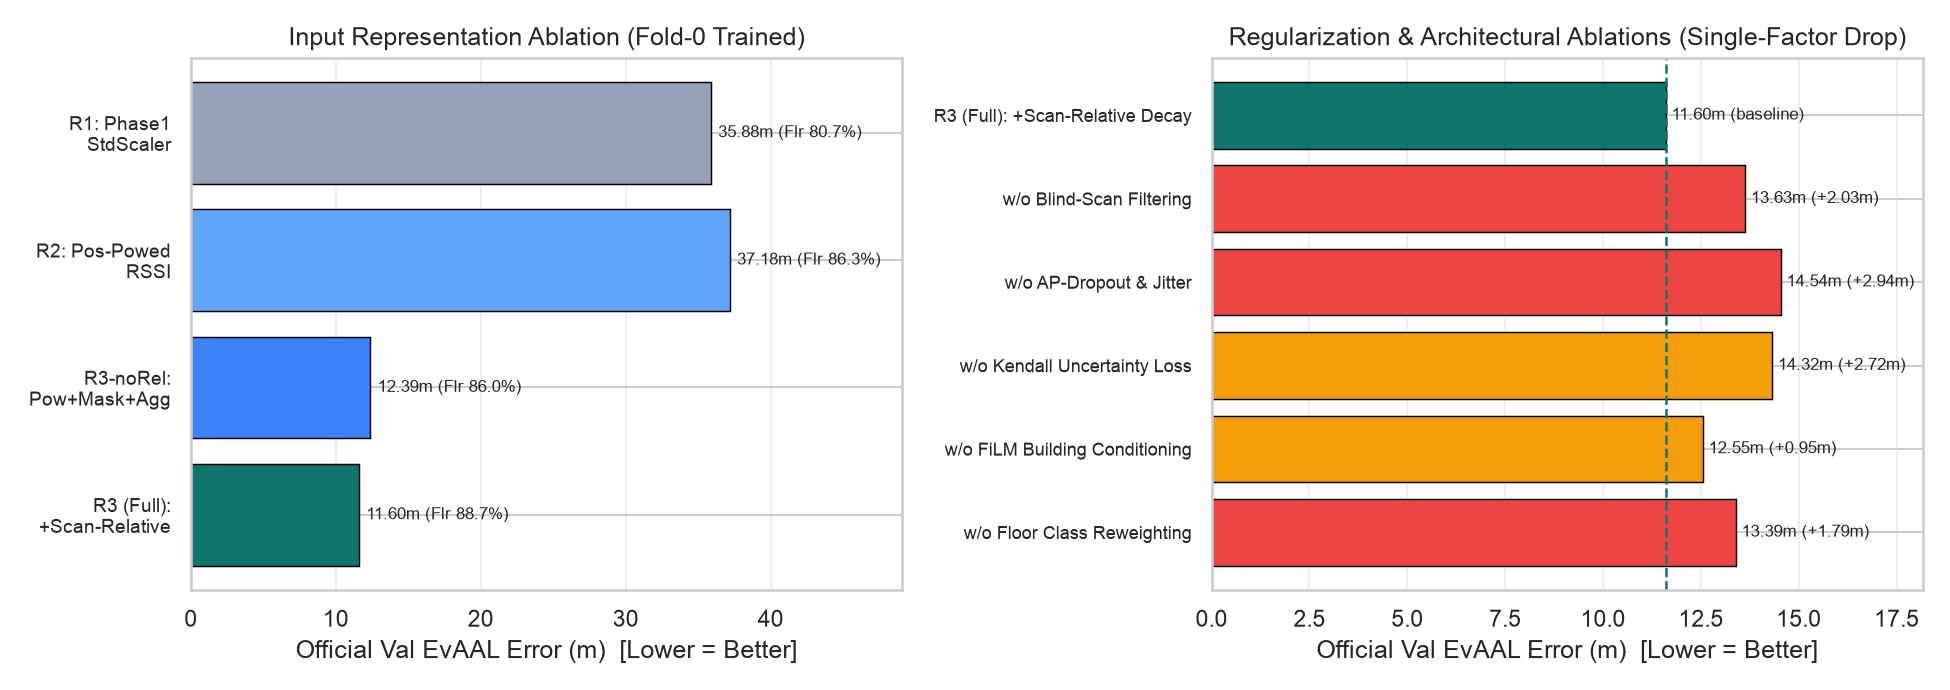

In [6]:
df_ab = pd.read_csv(P2_OUT / "ablation_results.csv")
display(df_ab[["group", "ablation", "in_dim", "fold0_evaal_m", "val_bld_acc", "val_flr_acc", "val_coord_mean_m", "val_coord_median_m", "val_evaal_m"]])

print("=== M1: NOISE AUGMENTATION & AP-DROPOUT GRID ===")
display(pd.read_csv(P2_OUT / "m1_noise_dropout_grid.csv"))

print("\n=== M4: LEARNING CURVE (SAMPLE EFFICIENCY ACROSS TRAINING USERS) ===")
display(pd.read_csv(P2_OUT / "m4_learning_curve.csv"))

print("\n=== M4: FLOOR CALIBRATION & EXPECTED CALIBRATION ERROR (ECE) ===")
display(pd.read_csv(P2_OUT / "m4_calibration_ece.csv"))

print("\n=== M4: THREE-SEED STABILITY & VARIANCE (SEEDS 42, 123, 999) ===")
display(pd.read_csv(P2_OUT / "m4_three_seed_variance.csv"))

df_ci = pd.read_csv(P2_OUT / "bootstrap_ci.csv")
print("\n=== PAIRED BOOTSTRAP 95% CONFIDENCE INTERVALS (1,000 RESAMPLES) ===")
display(df_ci)

with open(P2_OUT / "significance_tests.json") as f:
    print("\nPaired Significance & McNemar Tests:")
    print(json.dumps(json.load(f), indent=2))

show("p2_ablation_study.png")

## 6. Spatial Error Diagnostics, Floor Confusion & Device Robustness

Finally, we inspect the spatial error CDF, floor confusion matrices across Phase 1 XGBoost vs Pure DL vs Hybrid, spatial error map & worst 10% displacements, and hardware shift across the **11 validation phones** (2 seen phones: `397` scans; 9 unseen phones: `714` scans).

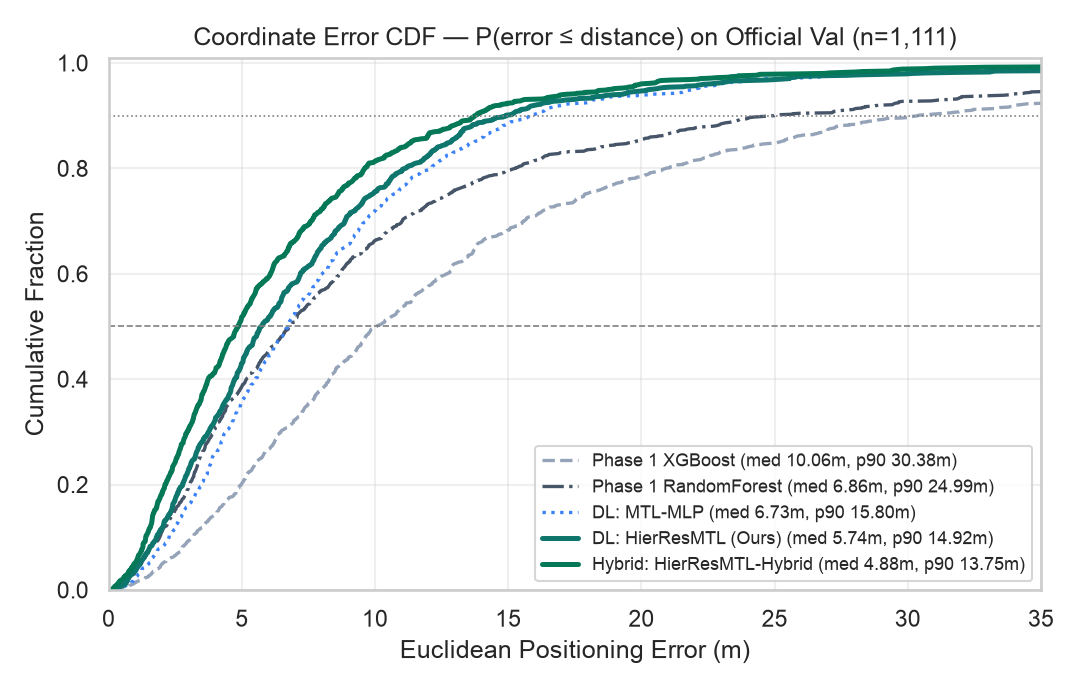

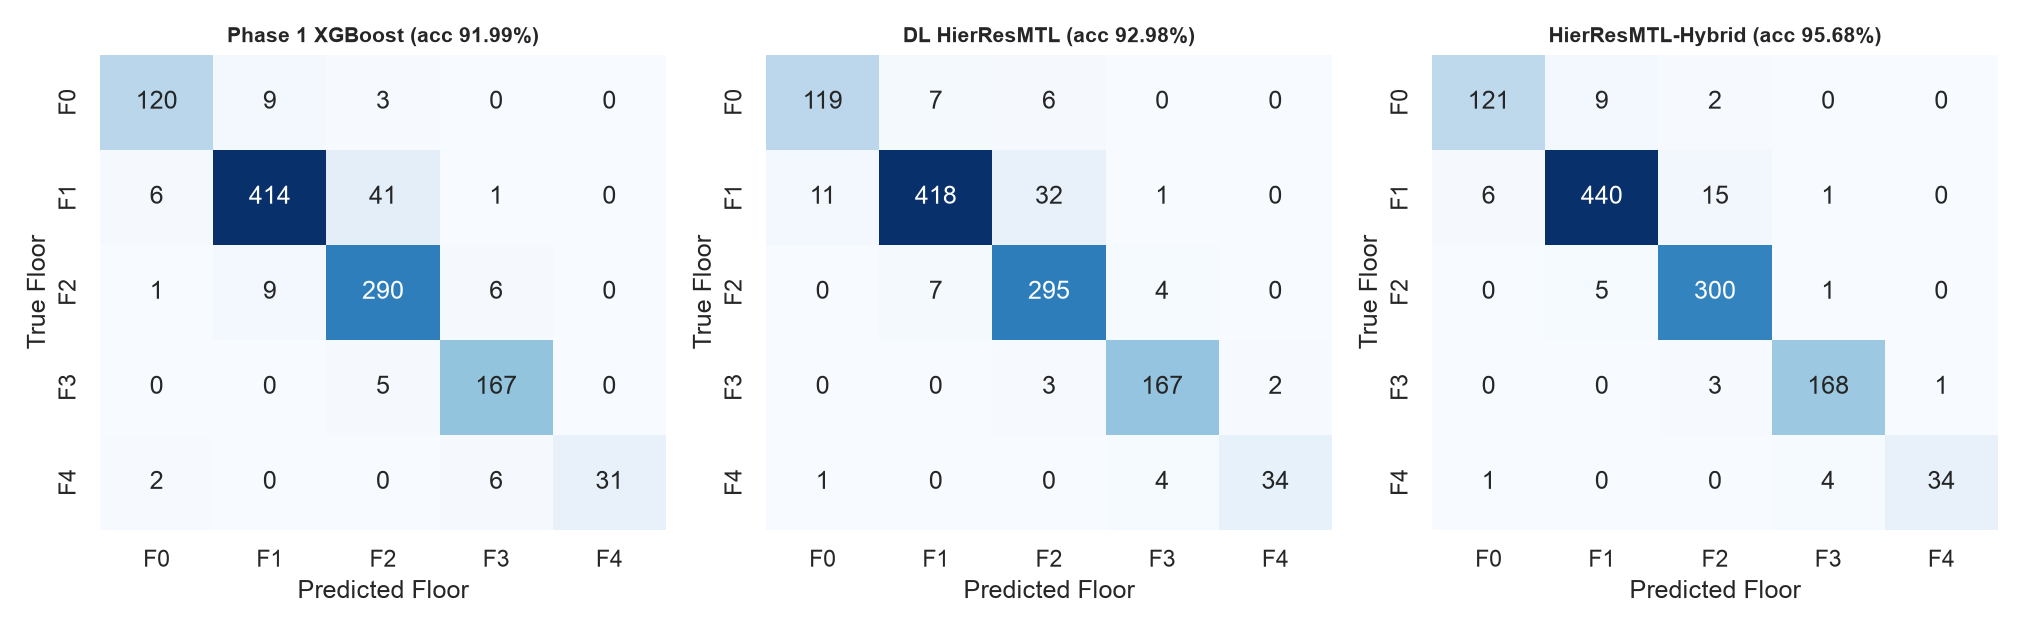

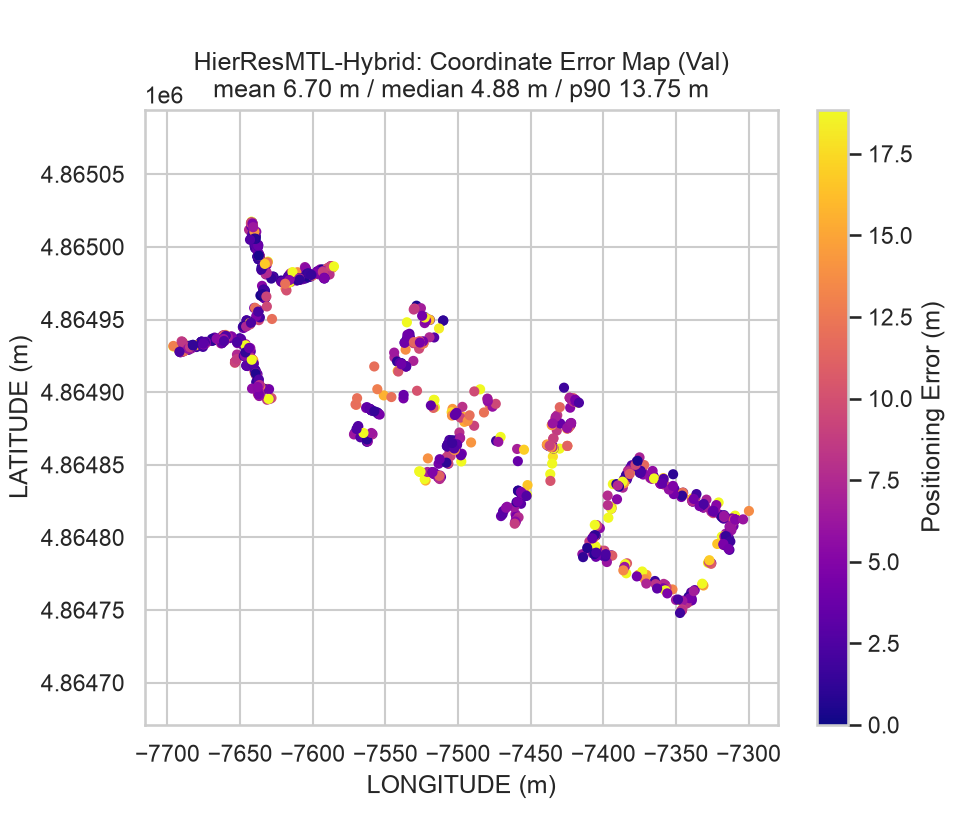

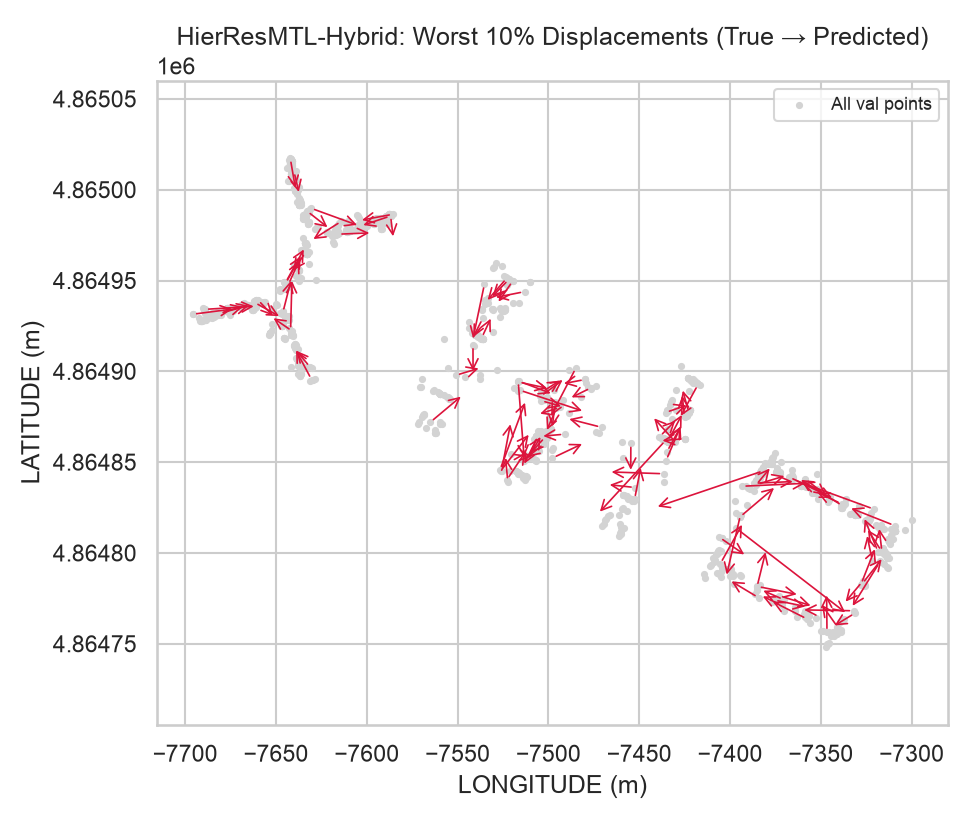

=== SEEN vs UNSEEN HANDSETS ===


,family,group,n_samples,floor_acc,coord_mean_m,coord_median_m
0,RandomForest,Seen (Phones 13 & 14),397,0.9169,10.13,5.14
1,RandomForest,Unseen (9 phones),714,0.9020,12.39,7.88
2,XGBoost,Seen (Phones 13 & 14),397,0.9395,14.14,8.82
3,XGBoost,Unseen (9 phones),714,0.9090,14.73,10.99
4,HierResMTL (DL),Seen (Phones 13 & 14),397,0.9471,6.36,4.75
5,HierResMTL (DL),Unseen (9 phones),714,0.9202,8.55,6.49
6,HierResMTL-Hybrid,Seen (Phones 13 & 14),397,0.9572,5.42,4.03
7,HierResMTL-Hybrid,Unseen (9 phones),714,0.9566,7.41,5.38



=== PHONE 14 HARDWARE OUTLIER RECOVERY ===


,family,phone,device_status,n,floor_acc,coord_mean_m,coord_median_m,coord_p95_m
7,RandomForest,14,Seen (shared),28,0.7500,30.45,16.84,116.09
18,XGBoost,14,Seen (shared),28,0.7857,29.56,24.00,79.82
29,HierResMTL (DL),14,Seen (shared),28,0.8214,12.43,11.25,28.98
40,HierResMTL-Hybrid,14,Seen (shared),28,0.7857,10.17,7.24,28.95


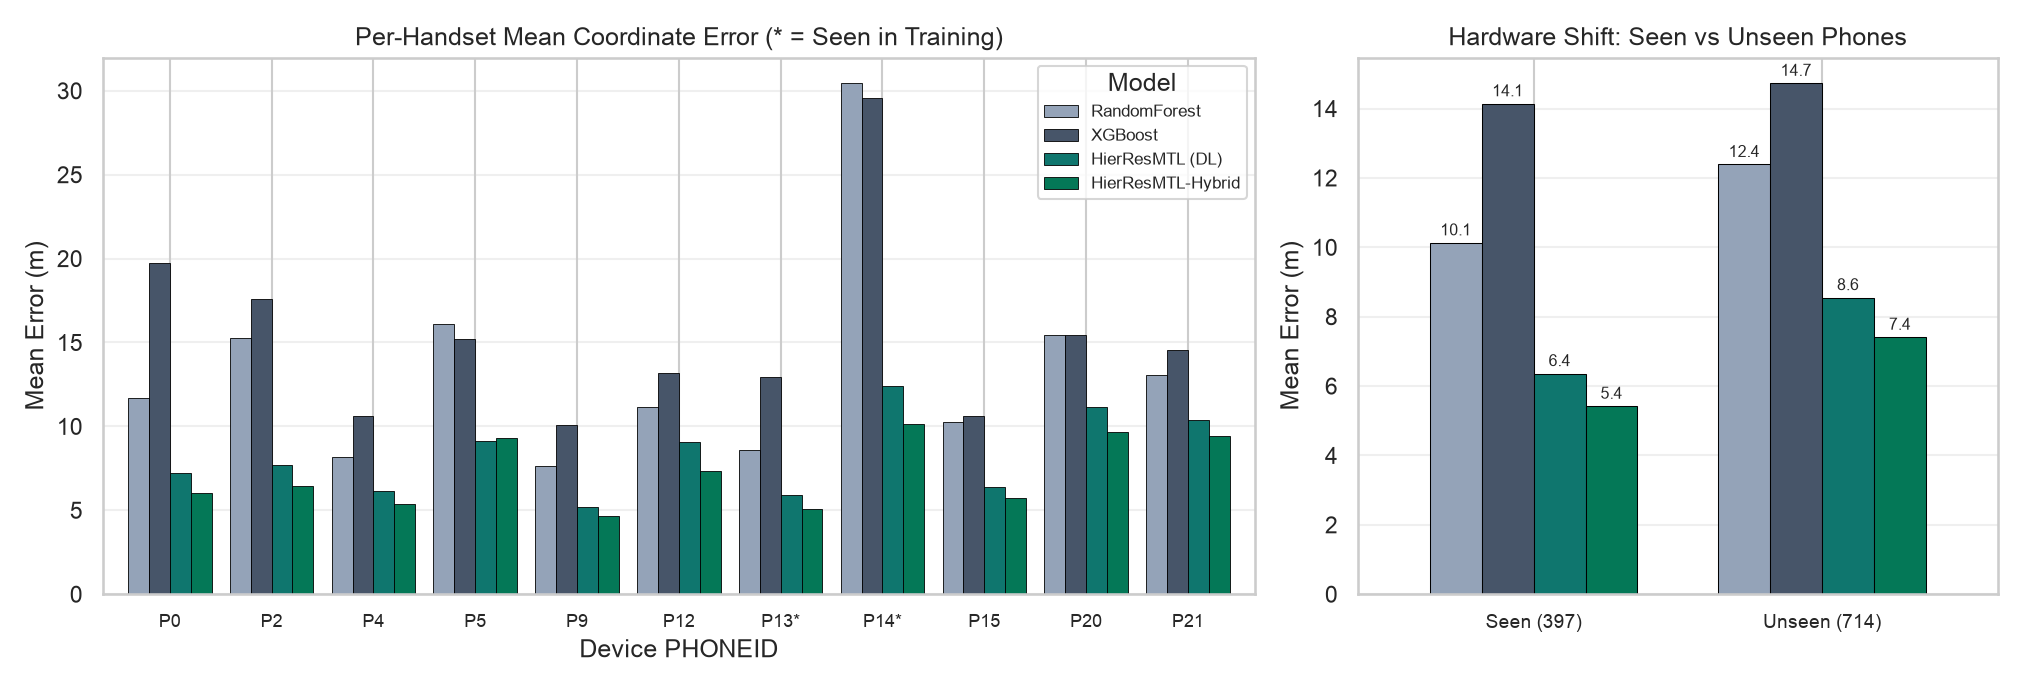

In [7]:
show("p2_error_cdf_comparison.png", "p2_confusion_floor_hybrid.png")
show("p2_error_map_hybrid.png", "p2_error_vectors_hybrid.png")

df_grp = pd.read_csv(P2_OUT / "robustness_seen_unseen.csv")
df_rob = pd.read_csv(P2_OUT / "robustness_by_phone.csv")
print("=== SEEN vs UNSEEN HANDSETS ===")
display(df_grp)
print("\n=== PHONE 14 HARDWARE OUTLIER RECOVERY ===")
display(df_rob[df_rob["phone"] == 14])

show("p2_robustness_by_phone.png")

## 7. Phase 2 Conclusions & Key Takeaways

1. **Multitask Deep Learning Works When Negative Transfer Is Addressed:** Plain `MTL_MLP` suffered slight building/OOF degradation (`13.33 m` OOF EvAAL) relative to `SingleTaskMLP` (`11.79 m`), while `HierResMTL` (Pre-LN ResNet + FiLM building modulation + Kendall uncertainty loss) achieved **10.93 m OOF EvAAL** and **8.09 m Val EvAAL**.
2. **Domain Representation Matters Most:** Switching from Phase 1's `StandardScaler` (`R1`) to device-invariant `R3` (positive-powed + scan-relative exponential decay) was the single largest accuracy lever across both DL and kNN models.
3. **True Hybrid Synergy (`HierResMTL-Hybrid`):** Combining calibrated neural + tree/kNN classification with building-conditioned adaptive cosine retrieval achieves **99.91% Building**, **95.68% Floor** (+3.69% over Phase 1 best, McNemar $p < 10^{-5}$), **4.25 m MAE**, **6.70 m Mean / 4.88 m Median Euclidean Error**, and **6.92 m EvAAL** (**-42.1% vs Phase 1 Combined 11.95 m**), while remaining the best model on **5-Fold `USERID` OOF (10.11 m EvAAL vs Phase 1 RF 18.21 m)**.
4. **Device Shift Mitigation:** On unseen handsets (`714` scans), `HierResMTL-Hybrid` maintains **95.66% floor accuracy** (virtually identical to **95.72%** on seen phones) and cuts the Phase 1 Phone 14 error outlier from **30.45 m** down to **10.17 m** (**-66.6%**).